In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pydicom
import qim3d
from pydicom.dataset import Dataset, FileDataset, FileMetaDataset
from pydicom.sequence import Sequence
from pydicom.tag import Tag
from pydicom.uid import (
    PYDICOM_IMPLEMENTATION_UID,
    UID,
    ExplicitVRLittleEndian,
    JPEGLSLossless,
    JPEGLSNearLossless,
    MultiFrameGrayscaleByteSecondaryCaptureImageStorage,
    MultiFrameGrayscaleWordSecondaryCaptureImageStorage,
    generate_uid,
)
from pydicom.valuerep import DSfloat

from comptest.constants import DATASETS_RECONSTRUCTIONS_DIR
from comptest.types import ReconstructionGeometry

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
DS_NAME = "Canislupus_CZM_712"

DS_DIR = DATASETS_RECONSTRUCTIONS_DIR / "CIL_basic_binned_2x2" / DS_NAME
ds_np = qim3d.io.load(
    DS_DIR,
    contains=DS_NAME + "_",
)
# ds_geometry = json.loads((DS_DIR / "geometry.json").read_text())

In [16]:
ds_geometry = ReconstructionGeometry.load_json(DS_DIR / "geometry.json")

In [17]:
target_dtype = np.uint16
target_dtype_info = np.iinfo(target_dtype)

# Affine transform to fit in [DT.MIN, DT.MAX]
shift = np.min(ds_np)
data_range = np.max(ds_np) - shift
scale = (target_dtype_info.max - target_dtype_info.min) / data_range

# Clip to ensure no funny business with floating point rounding errors
ds_np_dt = np.clip(
    np.rint((ds_np - shift) * scale + target_dtype_info.min),
    target_dtype_info.min,
    target_dtype_info.max,
).astype(target_dtype)


In [18]:
ds_np_dt.min()
ds_np_dt.max()

np.uint16(65535)

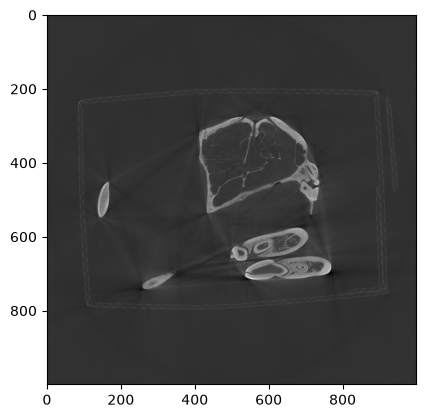

In [19]:
plt.imshow(ds_np_dt[512, :, :], cmap="gray")

In [20]:
from datetime import datetime
from pathlib import Path

import numpy as np


# Example:
# output_path = save_3d_dicom(arr, "volume.dcm")
# print(output_path)

In [21]:
def save_dicom(ds: FileDataset, output_path: str | Path) -> Path:
    """Save an array shaped (frames, rows, columns) as a multi-frame DICOM."""
    output_path = Path(output_path)

    output_path.parent.mkdir(parents=True, exist_ok=True)
    ds.save_as(output_path, write_like_original=False)
    return output_path


In [ ]:
def save_numpy_as_dicom(
    arr,
    output_path: str | Path,
    geometry: ReconstructionGeometry | None = None,
    compression: UID | None = None,
    compression_kwargs: dict | None = None,
) -> Path:
    """Save a (frames, rows, columns) NumPy array as multiframe DICOM."""

    def ds_number(value: float) -> DSfloat:
        """Create a valid DICOM Decimal String with at most 16 characters."""
        return DSfloat(float(value), auto_format=True)

    arr = np.asarray(arr)

    if arr.ndim != 3:
        raise ValueError(
            f"Expected array shape (frames, rows, columns), got {arr.shape}"
        )

    if arr.dtype not in (np.uint8, np.uint16, np.int16):
        raise TypeError("arr must have dtype uint8, uint16, or int16")

    frames, rows, columns = arr.shape

    if min(frames, rows, columns) <= 0:
        raise ValueError(f"Array dimensions must be positive, got {arr.shape}")

    # Multiframe grayscale SC requires unsigned stored pixels. Preserve int16
    # values using an unsigned representation plus a rescale intercept.
    if arr.dtype == np.int16:
        stored_array = (arr.astype(np.int32) - np.iinfo(np.int16).min).astype(np.uint16)
        rescale_intercept = -32768
    else:
        stored_array = arr
        rescale_intercept = 0

    if stored_array.dtype == np.uint8:
        sop_class_uid = MultiFrameGrayscaleByteSecondaryCaptureImageStorage
        bits_allocated = 8
    else:
        sop_class_uid = MultiFrameGrayscaleWordSecondaryCaptureImageStorage
        bits_allocated = 16

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    sop_instance_uid = generate_uid()

    file_meta = FileMetaDataset()
    file_meta.FileMetaInformationVersion = b"\x00\x01"
    file_meta.MediaStorageSOPClassUID = sop_class_uid
    file_meta.MediaStorageSOPInstanceUID = sop_instance_uid
    file_meta.TransferSyntaxUID = ExplicitVRLittleEndian
    file_meta.ImplementationClassUID = PYDICOM_IMPLEMENTATION_UID

    ds = FileDataset(
        str(output_path),
        {},
        file_meta=file_meta,
        preamble=b"\x00" * 128,
    )

    now = datetime.now()
    date = now.strftime("%Y%m%d")
    time = now.strftime("%H%M%S.%f")

    # SOP Common
    ds.SOPClassUID = sop_class_uid
    ds.SOPInstanceUID = sop_instance_uid

    # Patient Module: Type 2 attributes may be empty but must be present.
    ds.PatientName = ""
    ds.PatientID = ""
    ds.PatientBirthDate = ""
    ds.PatientSex = ""

    # General Study
    ds.StudyInstanceUID = generate_uid()
    ds.StudyDate = date
    ds.StudyTime = time
    ds.StudyID = ""
    ds.AccessionNumber = ""
    ds.ReferringPhysicianName = ""

    # General Series
    ds.SeriesInstanceUID = generate_uid()
    ds.SeriesNumber = 1
    ds.Modality = "OT"

    # General Image / Secondary Capture
    ds.InstanceNumber = 1
    ds.ImageType = ["DERIVED", "SECONDARY"]
    ds.ContentDate = date
    ds.ContentTime = time
    ds.ConversionType = "SYN"
    ds.BurnedInAnnotation = "NO"
    ds.PresentationLUTShape = "IDENTITY"

    # Image Pixel Module
    ds.NumberOfFrames = frames
    ds.Rows = rows
    ds.Columns = columns
    ds.SamplesPerPixel = 1
    ds.PhotometricInterpretation = "MONOCHROME2"
    ds.BitsAllocated = bits_allocated
    ds.BitsStored = bits_allocated
    ds.HighBit = bits_allocated - 1

    # Both multiframe grayscale SC SOP classes require unsigned stored pixels.
    ds.PixelRepresentation = 0

    # Required grayscale transformations.
    ds.RescaleSlope = ds_number(1)
    ds.RescaleIntercept = ds_number(rescale_intercept)
    ds.RescaleType = "US"

    if geometry is not None:
        dx = float(geometry.voxel_size_x_m) * 1e3
        dy = float(geometry.voxel_size_y_m) * 1e3
        dz = float(geometry.voxel_size_z_m) * 1e3

        if not all(np.isfinite(v) and v > 0 for v in (dx, dy, dz)):
            raise ValueError(
                f"Voxel dimensions must be finite and positive; "
                f"received {(dx, dy, dz)} mm"
            )

        # The presence of patient-space functional groups requires a frame of
        # reference.
        ds.FrameOfReferenceUID = generate_uid()
        ds.PositionReferenceIndicator = ""

        # Shared by all frames.
        pixel_measures = Dataset()
        pixel_measures.PixelSpacing = [
            ds_number(dy),  # row/Y spacing
            ds_number(dx),  # column/X spacing
        ]
        pixel_measures.SliceThickness = ds_number(dz)
        pixel_measures.SpacingBetweenSlices = ds_number(dz)

        plane_orientation = Dataset()
        plane_orientation.ImageOrientationPatient = [
            ds_number(1),
            ds_number(0),
            ds_number(0),
            ds_number(0),
            ds_number(1),
            ds_number(0),
        ]

        shared_group = Dataset()
        shared_group.PixelMeasuresSequence = Sequence([pixel_measures])
        shared_group.PlaneOrientationSequence = Sequence([plane_orientation])
        ds.SharedFunctionalGroupsSequence = Sequence([shared_group])

        # One position for every frame. This assumes:
        #   X = columns, Y = rows, Z = frame index
        # with the first voxel centered at patient coordinate (0, 0, 0).
        per_frame_groups = []

        for frame_index in range(frames):
            plane_position = Dataset()
            plane_position.ImagePositionPatient = [
                ds_number(0),
                ds_number(0),
                ds_number(frame_index * dz),
            ]

            frame_group = Dataset()
            frame_group.PlanePositionSequence = Sequence([plane_position])
            per_frame_groups.append(frame_group)

        ds.PerFrameFunctionalGroupsSequence = Sequence(per_frame_groups)

        # Frames are ordered by their per-frame functional-group information.
        ds.FrameIncrementPointer = Tag(0x5200, 0x9230)

    else:
        # FrameIncrementPointer is still required for multiframe SC. Without
        # geometry, use a simple page-number vector.
        ds.PageNumberVector = list(range(1, frames + 1))
        ds.FrameIncrementPointer = Tag(0x0018, 0x2001)

    little_endian_dtype = stored_array.dtype.newbyteorder("<")
    pixel_array = np.ascontiguousarray(
        stored_array.astype(little_endian_dtype, copy=False)
    )
    ds.PixelData = pixel_array.tobytes()

    if compression is not None:
        ds.compress(compression, **(compression_kwargs or {}))

    ds.save_as(output_path, enforce_file_format=True)
    return output_path

In [33]:
output_path = (
    DATASETS_RECONSTRUCTIONS_DIR
    / "CIL_basic_binned_2x2"
    / "DICOM_TEST"
    / DS_NAME
    / f"{DS_NAME}.dcm"
)

save_numpy_as_dicom(ds_np_dt, output_path, geometry=ds_geometry, compression=None)
save_numpy_as_dicom(
    ds_np_dt,
    output_path.with_name(f"{DS_NAME}_jpegls_ll.dcm"),
    geometry=ds_geometry,
    compression=JPEGLSLossless,
)

for jls_error in [25, 50]:
    save_numpy_as_dicom(
        ds_np_dt,
        output_path.with_name(f"{DS_NAME}_jpegls_nll_error{jls_error}.dcm"),
        geometry=ds_geometry,
        compression=JPEGLSNearLossless,
        compression_kwargs={"jls_error": jls_error},
    )


In [34]:
check = pydicom.dcmread(output_path)

pixel_measures = check.SharedFunctionalGroupsSequence[0].PixelMeasuresSequence[0]

print(pixel_measures.PixelSpacing)  # [dy, dx], mm
print(pixel_measures.SliceThickness)  # mm
print(pixel_measures.SpacingBetweenSlices)  # mm

[0.24152728312701, 0.24152728312701]
0.24152728312701
0.24152728312701


In [35]:
print("SOP class:", check.SOPClassUID)
print("SOP name:", check.SOPClassUID.name)
print("Frames:", check.get("NumberOfFrames", 1))
print("Root spacing:", check.get("PixelSpacing", "ABSENT"))

SOP class: 1.2.840.10008.5.1.4.1.1.7.3
SOP name: Multi-frame Grayscale Word Secondary Capture Image Storage
Frames: 1000
Root spacing: ABSENT


In [36]:
pm = check.SharedFunctionalGroupsSequence[0].PixelMeasuresSequence[0]

print(pm.PixelSpacing)
print(pm.SliceThickness)
print(pm.get("SpacingBetweenSlices"))

[0.24152728312701, 0.24152728312701]
0.24152728312701
0.24152728312701
